# 使用 MNIST 与 U-Net 训练 DDPM

本 Notebook 从零实现一个无条件 DDPM：将 MNIST 图像归一化到 $[-1,1]$，按随机时间步加入高斯噪声，用带时间条件的简化 U-Net 预测噪声，并通过 DDPM 反向过程从纯噪声生成手写数字。

训练目标为：

$$\mathcal{L}=\mathbb{E}_{x_0,t,\epsilon}\left[\lVert\epsilon-\epsilon_\theta(x_t,t)\rVert_2^2\right],$$

其中 $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$。建议使用 GPU；CPU 可先将 `EPOCHS` 设为 1 验证流程。

## 1. 导入依赖与设置随机种子

这一部分导入 PyTorch、TorchVision、NumPy 和绘图库，并固定随机种子，以提高实验的可复现性。若本地缺少依赖，可取消安装命令的注释并先运行一次。

In [1]:
# 如环境缺少依赖，可取消下一行注释：
# %pip install torch torchvision matplotlib numpy tqdm

import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 2. 集中配置超参数

这里集中控制批大小、训练轮数、学习率、扩散时间步数和模型宽度。`T=1000` 表示完整 DDPM 反向生成需要调用模型 1000 次；训练时每张图只随机抽取其中一个时间步。

In [2]:
DATA_DIR = Path("./data")
CHECKPOINT_PATH = Path("./mnist_unet_ddpm.pt")

BATCH_SIZE = 128
EPOCHS = 5          # CPU 建议先设为 1；GPU 可增加到 10 或更多
LEARNING_RATE = 2e-4
T = 1000
BETA_START = 1e-4
BETA_END = 2e-2
TIME_DIM = 128
BASE_CHANNELS = 32
GRAD_CLIP = 1.0

## 3. 加载并检查 MNIST

`ToTensor()` 将像素变为 $[0,1]$，随后 `Normalize(0.5, 0.5)` 将其映射到 $[-1,1]$。这个范围与生成阶段对预测干净图像的裁剪范围保持一致。

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,)),
])

dataset = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

images, labels = next(iter(loader))
print("images shape:", images.shape)
print("labels shape:", labels.shape)
print(f"pixel range: [{images.min().item():.1f}, {images.max().item():.1f}]")

images shape: torch.Size([128, 1, 28, 28])
labels shape: torch.Size([128])
pixel range: [-1.0, 1.0]


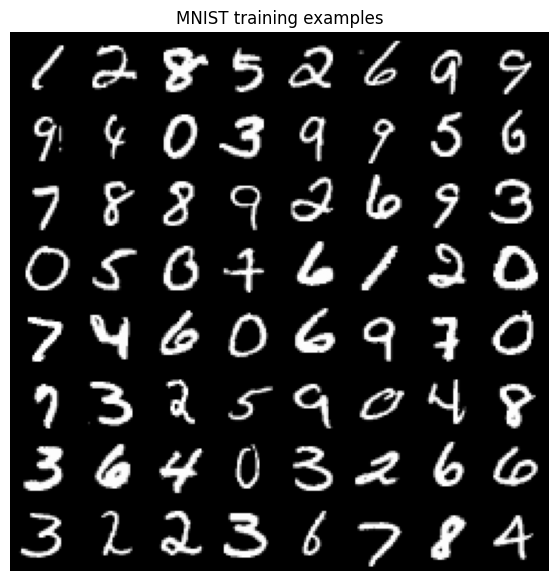

In [4]:
grid = make_grid((images[:64] + 1) / 2, nrow=8, padding=2)
plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0).clamp(0, 1), cmap="gray")
plt.axis("off")
plt.title("MNIST training examples")
plt.show()

## 4. 定义扩散噪声日程

线性 $\beta_t$ 日程决定每一步加入多少噪声。令 $\alpha_t=1-\beta_t$，累计乘积 $\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$。这些张量会同时用于前向加噪和反向采样，二者必须保持一致。

In [5]:
betas = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = torch.cat([torch.ones(1, device=device), alpha_bars[:-1]])

# q(x_{t-1} | x_t, x_0) 的后验方差
posterior_variance = betas * (1.0 - alpha_bars_prev) / (1.0 - alpha_bars)

print(f"alpha_bar[0]   = {alpha_bars[0].item():.6f}")
print(f"alpha_bar[-1]  = {alpha_bars[-1].item():.6f}")

alpha_bar[0]   = 0.999900
alpha_bar[-1]  = 0.000040


## 5. 前向加噪函数

`extract` 从长度为 $T$ 的日程中取出一个 batch 各自对应的系数，并调整成 `[B,1,1,1]` 以广播到整张图像。`q_sample` 使用闭式公式直接得到任意 $x_t$，训练时不需要逐步加噪。

In [6]:
def extract(values, t, x_shape):
    batch_size = t.shape[0]
    return values.gather(0, t).reshape(batch_size, *((1,) * (len(x_shape) - 1)))


def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_alpha_bar_t = extract(alpha_bars.sqrt(), t, x0.shape)
    sqrt_one_minus_alpha_bar_t = extract((1.0 - alpha_bars).sqrt(), t, x0.shape)
    xt = sqrt_alpha_bar_t * x0 + sqrt_one_minus_alpha_bar_t * noise
    return xt, noise

## 6. 可视化前向加噪

固定同一份高斯噪声，在不同时间观察信号逐渐消失。每一行对应一个时间步；接近 $t=999$ 时，图像应接近标准高斯噪声。

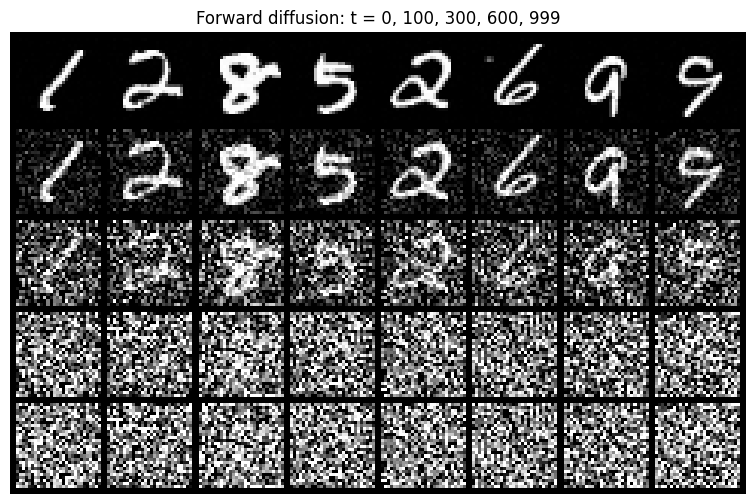

In [7]:
x0_demo = images[:8].to(device)
fixed_noise = torch.randn_like(x0_demo)
test_times = [0, 100, 300, 600, 999]
noisy_rows = []

for time_value in test_times:
    t_demo = torch.full((x0_demo.shape[0],), time_value, device=device, dtype=torch.long)
    xt_demo, _ = q_sample(x0_demo, t_demo, fixed_noise)
    noisy_rows.append(xt_demo.cpu())

grid = make_grid((torch.cat(noisy_rows) + 1) / 2, nrow=8, padding=2)
plt.figure(figsize=(10, 6))
plt.imshow(grid.permute(1, 2, 0).clamp(0, 1), cmap="gray")
plt.axis("off")
plt.title("Forward diffusion: t = 0, 100, 300, 600, 999")
plt.show()

## 7. 正弦时间编码

U-Net 必须知道当前噪声等级。正弦编码把标量时间步 $t$ 映射为多频率向量，再由 MLP 学习适合网络使用的时间特征。

In [8]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError("time embedding dimension must be even")
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2
        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(half_dim, device=t.device, dtype=torch.float32)
            / (half_dim - 1)
        )
        angles = t.float()[:, None] * frequencies[None, :]
        return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

## 8. 带时间条件的残差块

残差块先处理图像特征，再把时间向量投影到输出通道数，以 `[B,C,1,1]` 的形状广播到所有空间位置。若输入输出通道不同，旁路使用 $1\times1$ 卷积对齐维度。

In [9]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(1, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.norm2 = nn.GroupNorm(1, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.residual = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, kernel_size=1)
        )

    def forward(self, x, time_embedding):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_projection(time_embedding)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.residual(x)

## 9. 构造简化 U-Net

编码器将分辨率从 $28\times28$ 降到 $14\times14$、再到 $7\times7$；解码器逐步恢复分辨率，并拼接对应尺度的跳跃连接。网络最终输出与输入同形状的预测噪声，而不是直接输出数字类别或干净图像。

In [10]:
class TinyUNet(nn.Module):
    def __init__(self, time_dim=128, base_channels=32):
        super().__init__()
        c = base_channels
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.input_conv = nn.Conv2d(1, c, kernel_size=3, padding=1)

        self.down_block1 = ResidualBlock(c, 2 * c, time_dim)      # 28 x 28
        self.down_block2 = ResidualBlock(2 * c, 4 * c, time_dim)  # 14 x 14
        self.downsample = nn.AvgPool2d(2)

        self.middle_block = ResidualBlock(4 * c, 4 * c, time_dim)  # 7 x 7

        self.upsample2 = nn.ConvTranspose2d(4 * c, 4 * c, kernel_size=2, stride=2)
        self.up_block2 = ResidualBlock(8 * c, 2 * c, time_dim)
        self.upsample1 = nn.ConvTranspose2d(2 * c, 2 * c, kernel_size=2, stride=2)
        self.up_block1 = ResidualBlock(4 * c, c, time_dim)

        self.output_norm = nn.GroupNorm(1, c)
        self.output_conv = nn.Conv2d(c, 1, kernel_size=3, padding=1)

    def forward(self, x, t):
        time_embedding = self.time_mlp(t)
        x = self.input_conv(x)

        skip1 = self.down_block1(x, time_embedding)
        x = self.downsample(skip1)
        skip2 = self.down_block2(x, time_embedding)
        x = self.downsample(skip2)

        x = self.middle_block(x, time_embedding)

        x = self.upsample2(x)
        x = self.up_block2(torch.cat([x, skip2], dim=1), time_embedding)
        x = self.upsample1(x)
        x = self.up_block1(torch.cat([x, skip1], dim=1), time_embedding)

        return self.output_conv(F.silu(self.output_norm(x)))

## 10. 实例化模型并检查形状

扩散模型要求噪声预测与真实噪声逐像素比较，因此模型输出必须与输入严格保持 `[B,1,28,28]`。这里先做一次前向传播，在正式训练前尽早发现形状错误。

In [11]:
model = TinyUNet(time_dim=TIME_DIM, base_channels=BASE_CHANNELS).to(device)

test_x = torch.randn(4, 1, 28, 28, device=device)
test_t = torch.randint(0, T, (4,), device=device)
with torch.no_grad():
    test_output = model(test_x, test_t)

assert test_output.shape == test_x.shape
parameter_count = sum(p.numel() for p in model.parameters())
print("input shape: ", test_x.shape)
print("output shape:", test_output.shape)
print(f"parameters: {parameter_count:,}")

input shape:  torch.Size([4, 1, 28, 28])
output shape: torch.Size([4, 1, 28, 28])
parameters: 1,005,153


## 11. 训练噪声预测模型

每个 batch 独立抽取时间步 $t$ 与高斯噪声 $\epsilon$，构造 $x_t$，再最小化预测噪声和真实噪声之间的均方误差。梯度裁剪用于抑制偶发的梯度爆炸。运行本单元会开始实际训练。

In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_history = []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    progress = tqdm(loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for x0, _ in progress:
        x0 = x0.to(device, non_blocking=True)
        batch_size = x0.shape[0]
        t = torch.randint(0, T, (batch_size,), device=device, dtype=torch.long)
        xt, noise = q_sample(x0, t)
        predicted_noise = model(xt, t)
        loss = F.mse_loss(predicted_noise, noise)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        loss_value = loss.item()
        loss_history.append(loss_value)
        epoch_loss += loss_value
        progress.set_postfix(loss=f"{loss_value:.4f}")

    print(f"epoch={epoch + 1}, average_loss={epoch_loss / len(loader):.4f}")

Epoch 1/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch=1, average_loss=0.0705


Epoch 2/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch=2, average_loss=0.0340


Epoch 3/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch=3, average_loss=0.0313


Epoch 4/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch=4, average_loss=0.0288


Epoch 5/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch=5, average_loss=0.0283


## 12. 绘制训练损失

浅色曲线显示每一步的原始 MSE，深色曲线显示移动平均。由于每一步的图像、时间和噪声都随机，原始损失会波动；更应关注平滑曲线的整体下降趋势。

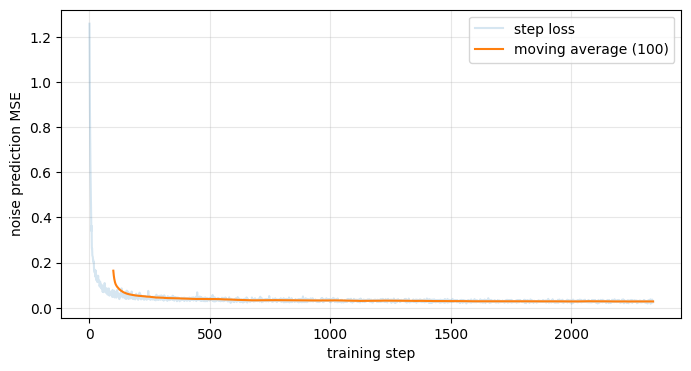

In [13]:
loss_array = np.asarray(loss_history)
window = min(100, len(loss_array))
smoothed = np.convolve(loss_array, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(loss_array, alpha=0.18, label="step loss")
plt.plot(range(window - 1, len(loss_array)), smoothed, label=f"moving average ({window})")
plt.xlabel("training step")
plt.ylabel("noise prediction MSE")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 13. 保存训练检查点

检查点同时保存模型参数、优化器状态、损失历史和关键超参数，便于恢复训练或在另一个会话中采样。

In [ ]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss_history": loss_history,
        "config": {
            "T": T,
            "beta_start": BETA_START,
            "beta_end": BETA_END,
            "time_dim": TIME_DIM,
            "base_channels": BASE_CHANNELS,
        },
    },
    CHECKPOINT_PATH,
)
print(f"checkpoint saved to: {CHECKPOINT_PATH.resolve()}")

## 14. 实现 DDPM 反向采样

从 $x_T\sim\mathcal{N}(0,I)$ 开始，U-Net 在每一步预测噪声并估计 $x_0$，随后依据后验 $q(x_{t-1}\mid x_t,x_0)$ 采样。除最后一步外，每一步都会重新加入与后验方差匹配的随机噪声，因此这是随机的 DDPM ancestral sampling，而不是确定性的 DDIM。

In [14]:
@torch.no_grad()
def p_sample(model, x, t):
    predicted_noise = model(x, t)

    alpha_bar_t = extract(alpha_bars, t, x.shape)
    alpha_bar_prev_t = extract(alpha_bars_prev, t, x.shape)
    alpha_t = extract(alphas, t, x.shape)
    beta_t = extract(betas, t, x.shape)

    predicted_x0 = (x - torch.sqrt(1.0 - alpha_bar_t) * predicted_noise) / torch.sqrt(alpha_bar_t)
    predicted_x0 = predicted_x0.clamp(-1.0, 1.0)

    posterior_mean_coef_x0 = beta_t * torch.sqrt(alpha_bar_prev_t) / (1.0 - alpha_bar_t)
    posterior_mean_coef_xt = (1.0 - alpha_bar_prev_t) * torch.sqrt(alpha_t) / (1.0 - alpha_bar_t)
    posterior_mean = posterior_mean_coef_x0 * predicted_x0 + posterior_mean_coef_xt * x

    variance_t = extract(posterior_variance, t, x.shape).clamp(min=1e-20)
    noise = torch.randn_like(x)
    nonzero_mask = (t != 0).float().reshape(x.shape[0], *((1,) * (x.ndim - 1)))
    return posterior_mean + nonzero_mask * torch.sqrt(variance_t) * noise


@torch.no_grad()
def sample_ddpm(model, n_samples=64):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=device)

    for time_value in tqdm(range(T - 1, -1, -1), desc="DDPM sampling"):
        t = torch.full((n_samples,), time_value, device=device, dtype=torch.long)
        x = p_sample(model, x, t)

    return x.clamp(-1.0, 1.0).cpu()

## 15. 生成并显示 MNIST 数字

运行此单元会执行完整的 1000 步 DDPM 采样。模型是无条件模型，因此不能指定数字类别；生成质量主要取决于训练轮数、模型容量和硬件训练时间。

DDPM sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

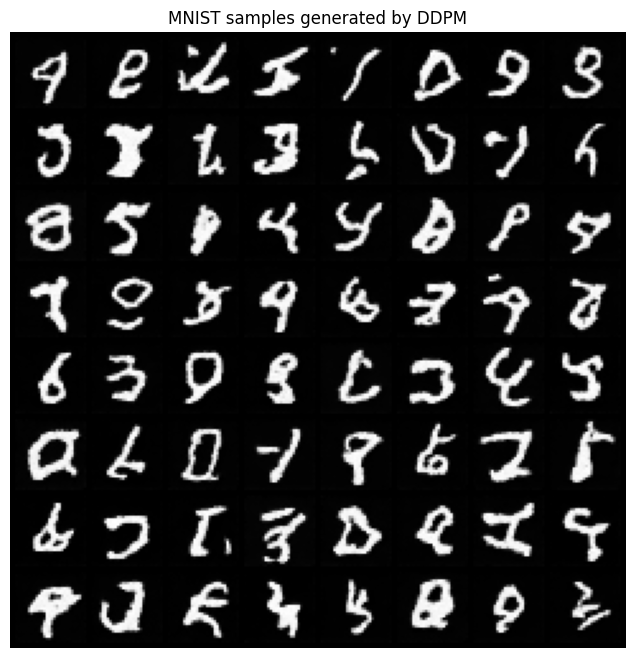

In [15]:
samples = sample_ddpm(model, n_samples=64)
display_samples = (samples + 1) / 2
grid = make_grid(display_samples, nrow=8, padding=2)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).clamp(0, 1), cmap="gray")
plt.axis("off")
plt.title("MNIST samples generated by DDPM")
plt.show()

## 16. 可选：从检查点恢复模型

重新打开 Notebook 时，可以先依次运行依赖、配置、噪声日程和模型定义，再运行下面的单元恢复参数，无需重复训练。

In [ ]:
# checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()
# print("model restored from checkpoint")

## 总结

完整数据流为：`MNIST x0 → 随机时间 t → 前向加噪 xt → U-Net 预测噪声 → MSE 更新参数`。生成时则从高斯噪声出发，连续执行 1000 次 DDPM 后验采样，最终得到 $28\times28$ 的灰度数字图像。